# Analyse a COCO Lab experiment export

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GauthamCodes/coco-labs/blob/main/docs/v2/r1/notebooks/analyse_experiment.ipynb)

Every experiment in COCO Lab's Workbench (and `coco experiment run spec.json --out dir/`)
exports the same files: `results.csv` (one row per run, failures and timeouts included),
`summary.json`, `spec.json`, `manifest.json` and `runs.jsonl`. This notebook loads one,
checks its checksums, **recomputes the summary from `results.csv`** with pandas and checks it
against `summary.json`, then draws the summary plots with matplotlib.

Evidence class: **MODEL** (coco_lab, the kinematic model that runs in the browser; not ROS 2,
not a robot). Counts (expansions, lengths, ticks, success) are the same on every device;
`compute_ms` is wall time on the device the manifest names.

Statistics, as COCO Lab computes them (`coco_lab/coco_lab/exp_stats.py`): success rates
with Wilson 95% intervals; medians and IQRs with linear-interpolation quantiles (Hyndman and
Fan type 7, pandas' default) over the runs where a metric is defined; paired comparisons on
shared scenarios with the Wilcoxon signed-rank test (exact up to 50 non-zero pairs), the
rank-biserial correlation and the Hodges-Lehmann shift, McNemar's exact test for success, and
Holm's adjustment across algorithm pairs.

In [1]:
import hashlib, json, math, urllib.request
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# An export directory (unzip a Workbench export here), or the committed reference results.
EXPORT = Path('../bench/depot-nav-100/planning')
RAW = 'https://raw.githubusercontent.com/GauthamCodes/coco-labs/main/docs/v2/r1/bench/depot-nav-100/planning/'
if not (EXPORT / 'results.csv').exists():          # e.g. in Colab: fetch the same files
    EXPORT = Path('export'); EXPORT.mkdir(exist_ok=True)
    for name in ('results.csv', 'summary.json', 'spec.json', 'manifest.json'):
        urllib.request.urlretrieve(RAW + name, EXPORT / name)
results = pd.read_csv(EXPORT / 'results.csv')
summary = json.loads((EXPORT / 'summary.json').read_text())
spec = json.loads((EXPORT / 'spec.json').read_text())
manifest = json.loads((EXPORT / 'manifest.json').read_text())
print(spec['title'] or spec['family'], '|', spec['world'], '|', len(results), 'runs |',
      'algorithms:', [a['id'] for a in spec['algorithms']])
print('digest', manifest['digest'], '| host', manifest['host'].get('runner'), manifest['host'].get('cpu'))

COCO-Bench v0 reference: depot-nav-100, planning | coco_depot_v1 | 600 runs | algorithms: ['bfs', 'dijkstra', 'astar', 'greedy', 'weighted_astar', 'dstar_lite']
digest 86876cd8e3dd3fd0c7b43c12230d176dcdb1f155f2e89f147b58af992ca3659c | host cpython 13th Gen Intel(R) Core(TM) i5-13420H


In [2]:
# Checksums: every file is the one the manifest describes.
for name, info in manifest['files'].items():
    p = EXPORT / name
    if p.exists():
        ok = hashlib.sha256(p.read_bytes()).hexdigest() == info['sha256']
        print(f'{name:14s} {info["bytes"]:>9d} B  sha256 {"matches" if ok else "DIFFERS"}')

results.csv       205885 B  sha256 matches
runs.jsonl        327691 B  sha256 matches
spec.json           2065 B  sha256 matches
summary.json       83295 B  sha256 matches


In [3]:
# Recompute the summary from results.csv and compare with summary.json.
Z = 1.959963984540054
def wilson(k, n):
    if n == 0: return None
    p, z2 = k / n, Z * Z
    den = 1 + z2 / n
    centre = (p + z2 / (2 * n)) / den
    half = Z * math.sqrt(p * (1 - p) / n + z2 / (4 * n * n)) / den
    return (0.0 if k == 0 else max(0.0, centre - half), 1.0 if k == n else min(1.0, centre + half))

metrics = [m['id'] for m in summary['metrics']]
rows, worst = [], 0.0
for g in summary['groups']:
    sel = results[(results.algorithm == g['algorithm']) & (results.sweep_index == g['sweep_index'])]
    k, n = int(sel.success.sum()), len(sel)
    lo, hi = wilson(k, n) or (None, None)
    assert (k, n) == (g['successes'], g['n']), g['algorithm']
    if g['success']:
        worst = max(worst, abs(lo - g['success']['low']), abs(hi - g['success']['high']))
    row = {'algorithm': g['algorithm'], 'sweep': g['sweep_index'], 'N': n, 'success': f'{k}/{n}',
           'wilson95': f'[{lo:.3f}, {hi:.3f}]' if n else '-'}
    for m in metrics:
        v = sel[m].dropna().astype(float)
        mine = (len(v), v.median() if len(v) else None, v.quantile(.25) if len(v) else None, v.quantile(.75) if len(v) else None)
        ref = g['metrics'][m]
        assert mine[0] == ref['n'], (g['algorithm'], m)
        for a, b in zip(mine[1:], (ref['median'], ref['q1'], ref['q3'])):
            if a is not None:
                worst = max(worst, abs(a - b) / max(1.0, abs(b)))
        if m in metrics[:3]:
            row[m] = f'{mine[1]:.4g} [{mine[2]:.4g}, {mine[3]:.4g}]' if mine[0] else '-'
    rows.append(row)
print(f'summary.json reproduced from results.csv: largest relative difference {worst:.2e}')
pd.DataFrame(rows)

summary.json reproduced from results.csv: largest relative difference 2.03e-16


,algorithm,sweep,N,success,wilson95,expansions,pushes,path_length_m
0,bfs,0,100,100/100,"[0.963, 1.000]","7.872e+04 [3.891e+04, 9.958e+04]","7.914e+04 [3.929e+04, 9.99e+04]","30.15 [24.01, 37.54]"
1,dijkstra,0,100,100/100,"[0.963, 1.000]","7.59e+04 [4.142e+04, 1.019e+05]","7.647e+04 [4.198e+04, 1.023e+05]","30.21 [24.19, 38.73]"
2,astar,0,100,100/100,"[0.963, 1.000]","1.287e+04 [4060, 2.232e+04]","1.334e+04 [4688, 2.319e+04]","30.21 [24.19, 38.73]"
3,greedy,0,100,100/100,"[0.963, 1.000]","887 [268, 3247]","1520 [837.8, 4196]","31.4 [24.95, 41.42]"
4,weighted_astar,0,100,100/100,"[0.963, 1.000]","1651 [427.5, 6340]","2546 [1017, 7154]","30.45 [24.35, 39.03]"
5,dstar_lite,0,100,100/100,"[0.963, 1.000]","1.106e+04 [5242, 1.818e+04]",-,"30.21 [24.19, 38.73]"


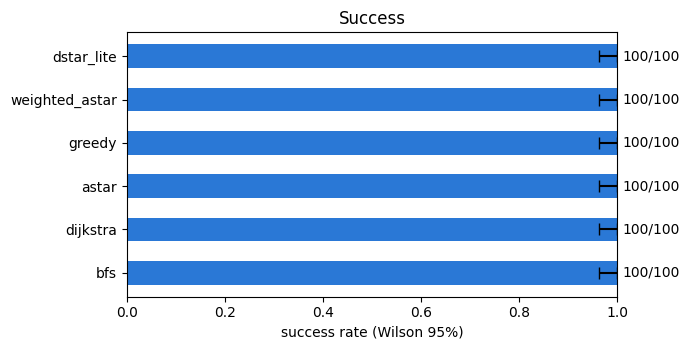

In [4]:
# Success rate per algorithm, Wilson 95% interval (sweep point 0).
g0 = [g for g in summary['groups'] if g['sweep_index'] == 0]
fig, ax = plt.subplots(figsize=(7, 0.6 + 0.5 * len(g0)))
for i, g in enumerate(g0):
    s = g['success']
    ax.barh(i, s['rate'] if s else 0, color='#2a78d6', height=0.55)
    if s:
        ax.errorbar(s['rate'], i, xerr=[[s['rate'] - s['low']], [s['high'] - s['rate']]], color='black', capsize=4)
    ax.text(1.01, i, f"{g['successes']}/{g['n']}", va='center')
ax.set_yticks(range(len(g0)), [g['algorithm'] for g in g0]); ax.set_xlim(0, 1)
ax.set_xlabel('success rate (Wilson 95%)'); ax.set_title('Success')
plt.tight_layout(); plt.show()

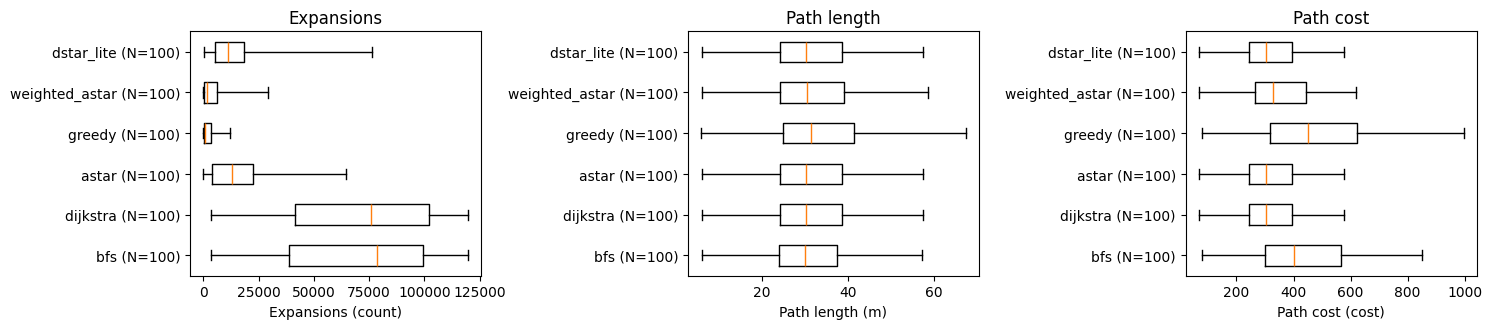

In [5]:
# Box plots: quartile box, median, whiskers to min and max (as the Workbench draws them).
shown = [m for m in summary['metrics'] if m['test'] and not m['timing']][:3]
fig, axes = plt.subplots(1, len(shown), figsize=(5 * len(shown), 3.4))
for ax, m in zip(axes if len(shown) > 1 else [axes], shown):
    data = [results[(results.algorithm == g['algorithm']) & (results.sweep_index == 0)][m['id']].dropna() for g in g0]
    ax.boxplot(data, vert=False, whis=(0, 100), tick_labels=[f"{g['algorithm']} (N={len(d)})" for g, d in zip(g0, data)])
    ax.set_xlabel(f"{m['label']} ({m['unit']})"); ax.set_title(m['label'])
plt.tight_layout(); plt.show()

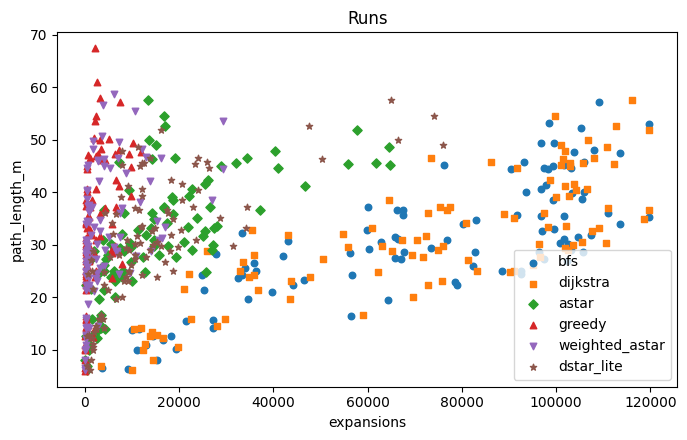

In [6]:
# One point per run.
x, y = ('expansions', 'path_length_m') if spec['family'] == 'planning' else (shown[0]['id'], shown[1]['id'])
fig, ax = plt.subplots(figsize=(7, 4.5))
for i, (alg, part) in enumerate(results[results.sweep_index == 0].groupby('algorithm', sort=False)):
    ax.scatter(part[x], part[y], s=22, label=alg, marker='osD^v*'[i % 6])
ax.set_xlabel(x); ax.set_ylabel(y); ax.legend(); ax.set_title('Runs')
plt.tight_layout(); plt.show()

In [7]:
# Paired comparisons on shared scenarios (from summary.json), for one metric.
metric = shown[0]['id']
pd.DataFrame([{'A': p['a'], 'B': p['b'], 'pairs': p['metrics'][metric]['n_pairs'],
               'median diff': p['metrics'][metric]['median_diff'],
               'Hodges-Lehmann': p['metrics'][metric]['hodges_lehmann'],
               'rank-biserial r': p['metrics'][metric]['rank_biserial'],
               'p': p['metrics'][metric]['p'], 'p (Holm)': p['metrics'][metric].get('p_holm'),
               'verdict': p['metrics'][metric].get('verdict'), 'why no test': p['metrics'][metric]['reason']}
              for p in summary['paired'] if p['sweep_index'] == 0])

,A,B,pairs,median diff,Hodges-Lehmann,rank-biserial r,p,p (Holm),verdict,why no test
0,bfs,dijkstra,100,-998.0,-1187.00,-0.294653,1.057631e-02,2.115263e-02,significant difference,None
1,bfs,astar,100,57378.0,54974.50,1.000000,3.955911e-18,5.933533e-17,significant difference,None
2,bfs,greedy,100,76503.0,67938.00,1.000000,3.955911e-18,5.933533e-17,significant difference,None
3,bfs,weighted_astar,100,75725.0,65996.50,1.000000,3.955688e-18,5.933533e-17,significant difference,None
4,bfs,dstar_lite,100,56076.5,56004.25,1.000000,3.955911e-18,5.933533e-17,significant difference,None
5,dijkstra,astar,100,58413.5,55920.50,1.000000,3.955911e-18,5.933533e-17,significant difference,None
6,dijkstra,greedy,100,74214.0,69165.00,1.000000,3.955911e-18,5.933533e-17,significant difference,None
7,dijkstra,weighted_astar,100,72877.0,67120.00,1.000000,3.955911e-18,5.933533e-17,significant difference,None
8,dijkstra,dstar_lite,100,59540.0,56733.75,1.000000,3.955911e-18,5.933533e-17,significant difference,None
9,astar,greedy,100,9037.5,11209.50,0.992991,1.426828e-17,7.134142e-17,significant difference,None


Every run is in `results.csv`, failures and timeouts included; a metric that is
undefined for a run (for example path length when no path was found) is empty there and is
excluded from that metric's N, which is always reported. Re-running the spec — in the
browser from its link, or with `coco experiment run spec.json --out dir/` — gives the same
counts and the same digest.